# Readout learning, regression and multi-start search

Besides gradient-based optimizers, `braintools.optim` has tools for problems with more structure:

1. **FORCE learning** (`FORCE`): train the linear readout of a chaotic recurrent rate network online, so that the network produces a target signal on its own.
2. **Online least squares** (`RLS`, `LMS`) against the closed-form `ridge_regression` on the same linear problem.
3. **Sparse regression** (`lasso_regression`, `elastic_net_regression`): how the number of selected features shrinks as the penalty `alpha` grows.
4. **Multi-start minimization** (`multistart_minimize`): a local optimizer run from hundreds of starting points at once on a multimodal function.

Every repeated model step below runs inside `brainstate.transform.for_loop`, which compiles the whole time loop into one XLA program.

In [1]:
import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools
from braintools.optim import (
    FORCE, LMS, RLS,
    elastic_net_regression, lasso_regression, ridge_regression,
    multistart_init, multistart_minimize,
)

## 1. FORCE learning on a chaotic rate network

The network has $N$ rate units with state $x$, rates $r = \tanh(x)$ and a linear readout $z = w^\top r$ that is fed back into every unit:

$$\tau \dot x = -x + J r + w_{fb}\, z .$$

The recurrent weights $J_{ij} \sim \mathcal N(0, g^2/N)$ with gain $g = 1.5 > 1$ make the network chaotic when the readout is silent. FORCE learning (Sussillo and Abbott, 2009) trains only $w$, by recursive least squares at every time step, so that $z$ follows a target $f(t)$. Because the RLS update is strong from the first step, the error stays small throughout, the fed-back signal is close to the target, and the network's chaos is tamed into the periodic activity that generates $f$.

The target here is a sum of three sines with periods of 240, 120 and 60 ms. The state lives in `brainstate` states: `x` is a `HiddenState`, the readout `w` a `ParamState` registered with the optimizer.

In [2]:
N, g, dt, tau = 400, 1.5, 1.0, 10.0          # time in ms
k_J, k_fb, k_x = jax.random.split(jax.random.PRNGKey(0), 3)
J = g * jax.random.normal(k_J, (N, N)) / jnp.sqrt(N)
w_fb = jax.random.uniform(k_fb, (N,), minval=-1.0, maxval=1.0)

x = brainstate.HiddenState(0.5 * jax.random.normal(k_x, (N,)))
w = brainstate.ParamState(jnp.zeros((N, 1)))
force = FORCE(alpha=1.0)
force.register_trainable_weights({'readout': w})


def target_fn(t):
    return (jnp.sin(2 * jnp.pi * t / 240.) + 0.5 * jnp.sin(2 * jnp.pi * t / 120.)
            + 0.25 * jnp.sin(2 * jnp.pi * t / 60.)) / 1.5


def step(target, train):
    # One Euler step of the network; with train=True, one FORCE update of the readout.
    r = jnp.tanh(x.value)
    z = r @ w.value                                  # readout, shape (1,)
    x.value = x.value + dt / tau * (-x.value + J @ r + w_fb * z[0])
    if train:
        w_old = w.value
        force.step(r[None], z[None], target[None])   # inputs, current output, target
        dw = jnp.linalg.norm(w.value - w_old)
    else:
        dw = jnp.zeros(())
    return z[0], r[:5], dw

The run has three phases, each a single `for_loop` over the target samples: 1 s of spontaneous activity (the readout is still zero, so there is no feedback), 6 s of training, and 2 s of testing with learning switched off, where the network runs on its own feedback.

In [3]:
T_pre, T_train, T_test = 1000, 6000, 2000
t = jnp.arange(T_pre + T_train + T_test) * dt
f = target_fn(t)[:, None]
f_pre, f_train, f_test = f[:T_pre], f[T_pre:T_pre + T_train], f[T_pre + T_train:]

z_pre, r_pre, _ = brainstate.transform.for_loop(lambda y: step(y, False), f_pre)
z_train, r_train, dw_train = brainstate.transform.for_loop(lambda y: step(y, True), f_train)
z_test, r_test, _ = brainstate.transform.for_loop(lambda y: step(y, False), f_test)

def mse(z, y):
    return float(jnp.mean((z - y[:, 0]) ** 2))

print('target variance:            %.4f' % float(jnp.var(f)))
print('training MSE, first 500 ms: %.2e' % mse(z_train[:500], f_train[:500]))
print('training MSE, last 500 ms:  %.2e' % mse(z_train[-500:], f_train[-500:]))
print('test MSE (no learning):     %.2e' % mse(z_test, f_test))

target variance:            0.2916
training MSE, first 500 ms: 1.43e-03
training MSE, last 500 ms:  7.02e-06


test MSE (no learning):     1.19e-04


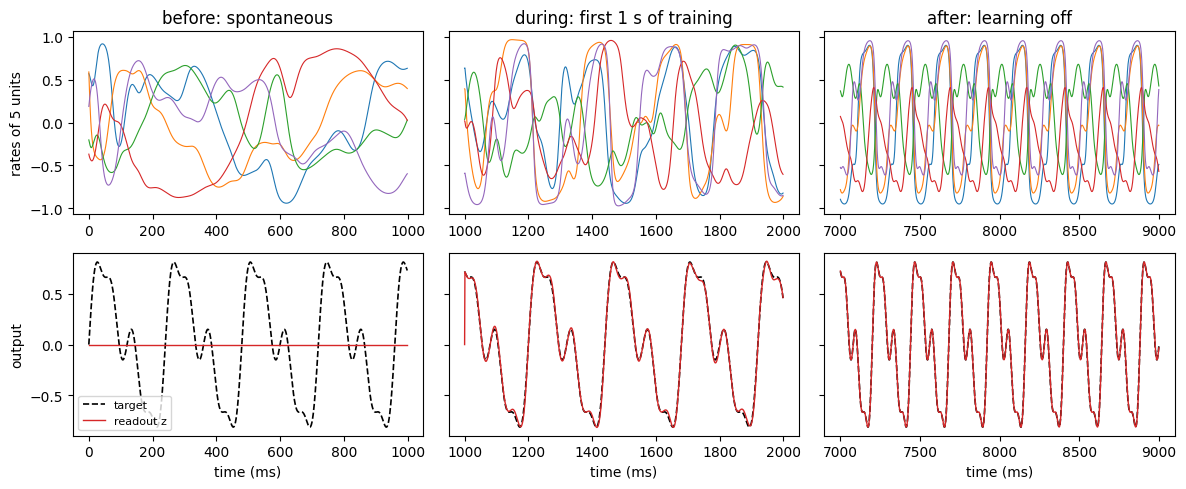

In [4]:
segments = [('before: spontaneous', t[:T_pre], r_pre, z_pre, f_pre),
            ('during: first 1 s of training', t[T_pre:T_pre + 1000], r_train[:1000], z_train[:1000], f_train[:1000]),
            ('after: learning off', t[T_pre + T_train:], r_test, z_test, f_test)]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharey='row')
for col, (title, ts, rates, z, y) in enumerate(segments):
    axes[0, col].plot(ts, rates, lw=0.8)
    axes[0, col].set_title(title)
    axes[1, col].plot(ts, y[:, 0], 'k--', lw=1.2, label='target')
    axes[1, col].plot(ts, z, color='tab:red', lw=1, label='readout z')
    axes[1, col].set_xlabel('time (ms)')
axes[0, 0].set_ylabel('rates of 5 units')
axes[1, 0].set_ylabel('output')
axes[1, 0].legend(loc='lower left', fontsize=8)
plt.tight_layout()

Before training the readout is zero and the units fluctuate irregularly: this is the chaotic regime of $g = 1.5$. Within a few steps of training the readout follows the target closely (a training MSE of 1.4e-3 over the first 500 ms, against a target variance of 0.29), and the unit activity becomes periodic, locked to the 240 ms period of the target. By the end of training the error has fallen to 7.0e-6. With learning switched off, the network keeps generating the target from its own feedback, with a test MSE of 1.2e-4.

The size of each readout update, $\|\Delta w\|$, shows the learning settling down, while the error stays small throughout, so FORCE never has to correct large deviations:

mean |dw| over the first / last 100 steps: 3.6e-03 / 6.3e-05


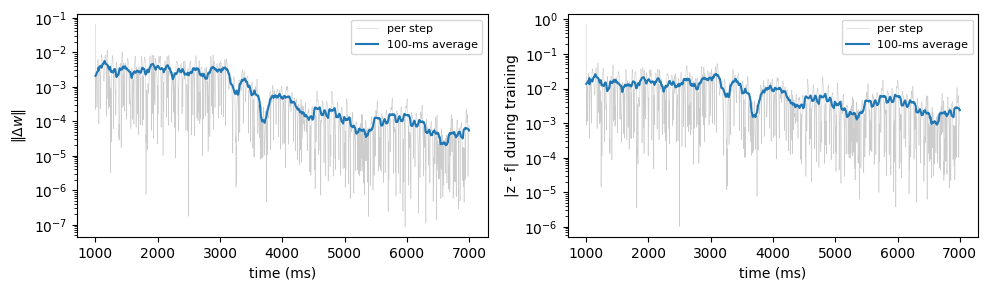

In [5]:
err_train = np.abs(np.asarray(z_train) - np.asarray(f_train[:, 0]))
dw = np.asarray(dw_train)
window = np.ones(100) / 100                       # 100-ms moving average
t_ms = np.asarray(t[T_pre:T_pre + T_train])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].semilogy(t_ms, dw, color='0.8', lw=0.4, label='per step')
axes[0].semilogy(t_ms, np.convolve(dw, window, mode='same'), lw=1.5, label='100-ms average')
axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel(r'$\|\Delta w\|$'); axes[0].legend(fontsize=8)
axes[1].semilogy(t_ms, err_train, color='0.8', lw=0.4, label='per step')
axes[1].semilogy(t_ms, np.convolve(err_train, window, mode='same'), lw=1.5, label='100-ms average')
axes[1].set_xlabel('time (ms)'); axes[1].set_ylabel('|z - f| during training'); axes[1].legend(fontsize=8)
plt.tight_layout()
print('mean |dw| over the first / last 100 steps: %.1e / %.1e'
      % (float(dw_train[:100].mean()), float(dw_train[-100:].mean())))

## 2. Online least squares: `RLS`, `LMS` and `ridge_regression`

FORCE is RLS applied inside a recurrent network. On a plain linear problem $y = X w + \varepsilon$, RLS with forgetting factor 1 does something exact: after any number of samples its weights equal the ridge solution

$$\arg\min_W \|Y - X W\|^2 + \alpha \|W\|^2$$

over the samples seen so far (with zero initial weights and $P_0 = I/\alpha$). Here 400 noisy samples with 20 features are fed to `RLS` one at a time inside a `for_loop`, recording the weights after every sample:

In [6]:
rng = np.random.default_rng(0)
n, d, alpha = 400, 20, 5.0
X = rng.normal(size=(n, d)).astype(np.float32)
w_true = rng.normal(size=(d, 1)).astype(np.float32)
Y = X @ w_true + 0.5 * rng.normal(size=(n, 1)).astype(np.float32)

w_rls = brainstate.ParamState(jnp.zeros((d, 1)))
rls = RLS(alpha=alpha)
rls.register_trainable_weights({'w': w_rls})

def rls_step(x_i, y_i):
    rls.step(x_i[None], None, y_i[None])     # outputs=None: computed as x @ w
    return w_rls.value[:, 0]

w_history = brainstate.transform.for_loop(rls_step, jnp.asarray(X), jnp.asarray(Y))

ridge_all = ridge_regression(X, Y, alpha=alpha, fit_intercept=False)
ridge_50 = ridge_regression(X[:50], Y[:50], alpha=alpha, fit_intercept=False)
print('max |RLS - ridge|, all 400 samples:   %.1e' % float(jnp.max(jnp.abs(w_rls.value - ridge_all.coef))))
print('max |RLS - ridge|, first 50 samples:  %.1e' % float(jnp.max(jnp.abs(w_history[49] - ridge_50.coef[:, 0]))))

max |RLS - ridge|, all 400 samples:   1.8e-06
max |RLS - ridge|, first 50 samples:  8.9e-07


The two agree to float32 rounding (about 1e-6), after all 400 samples and after the first 50 alike: RLS needs no learning rate, and after every sample it holds the best regularised fit to the data seen so far. The price is the $d \times d$ matrix $P$ that it updates at every step.

`LMS` (Widrow-Hoff) is the first-order counterpart: $w \leftarrow w - \eta\, x\, e$ per sample, with no $P$ matrix. It is cheaper per step but needs a learning rate, and it is stable only for $\eta < 2/\|x\|^2$, about $2/d = 0.1$ here. Each run below is one `for_loop` over the same samples:

|w - w_true| after 400 samples:
  ridge (closed form): 0.094
  RLS:                 0.094
  LMS lr=0.002          1.89
  LMS lr=0.01           0.238
  LMS lr=0.05           0.66
  LMS lr=0.12           1.54e+05


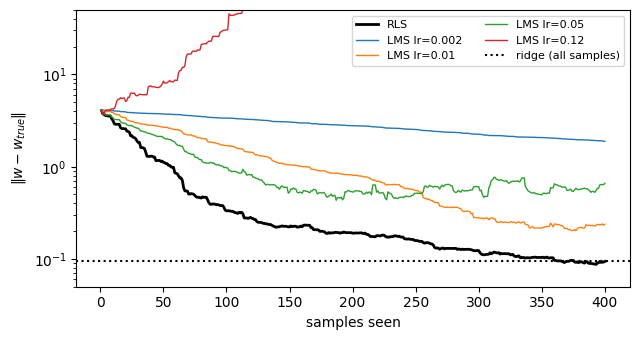

In [7]:
def run_lms(lr):
    w_lms = brainstate.ParamState(jnp.zeros((d, 1)))
    lms = LMS(lr=lr)
    lms.register_trainable_weights({'w': w_lms})

    def lms_step(x_i, y_i):
        lms.step(x_i[None], None, y_i[None])
        return jnp.linalg.norm(w_lms.value[:, 0] - w_true[:, 0])

    return np.asarray(brainstate.transform.for_loop(lms_step, jnp.asarray(X), jnp.asarray(Y)))


lms_rates = [0.002, 0.01, 0.05, 0.12]
lms_errors = {lr: run_lms(lr) for lr in lms_rates}
rls_error = np.asarray(jnp.linalg.norm(w_history - w_true[:, 0], axis=1))
ridge_error = float(jnp.linalg.norm(ridge_all.coef - w_true))

print('|w - w_true| after 400 samples:')
print('  ridge (closed form): %.3f' % ridge_error)
print('  RLS:                 %.3f' % rls_error[-1])
for lr in lms_rates:
    print('  LMS lr=%-5g          %.3g' % (lr, lms_errors[lr][-1]))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
samples = np.arange(1, n + 1)
ax.semilogy(samples, rls_error, 'k', lw=2, label='RLS')
for lr in lms_rates:
    ax.semilogy(samples, lms_errors[lr], lw=1, label=f'LMS lr={lr}')
ax.axhline(ridge_error, color='k', ls=':', label='ridge (all samples)')
ax.set_ylim(0.05, 50); ax.set_xlabel('samples seen'); ax.set_ylabel(r'$\|w - w_{true}\|$')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()

RLS ends at the ridge solution, 0.094 away from the true weights; that remaining error comes from the measurement noise and cannot be removed. The LMS runs show the learning-rate trade-off. With `lr=0.002` LMS is still far off after 400 samples (1.89). `lr=0.05` descends fastest at first but then stalls at a noise floor (0.66 at the end), because with a constant learning rate every noisy sample keeps pushing the weights around. `lr=0.01` is the best of these rates (0.238). `lr=0.12` is above the stability limit and diverges (1.5e5).

## 3. Sparse regression: lasso and elastic net

When only a few of many features matter, an $L_1$ penalty sets the other coefficients exactly to zero. `lasso_regression` minimises the objective of scikit-learn's `Lasso`,

$$\frac{1}{2n}\|y - X w - b\|^2 + \alpha \|w\|_1 ,$$

and `elastic_net_regression` adds an $L_2$ term, $\alpha\left(\rho \|w\|_1 + \tfrac{1-\rho}{2}\|w\|^2\right)$ with $\rho$ = `l1_ratio`. Both are solved by FISTA inside a `lax.while_loop`, so they can be `jax.vmap`-ped over `alpha` to compute a whole regularisation path in one call.

The problem has 80 samples and 40 features, of which only the first 5 have non-zero true coefficients:

In [8]:
rng = np.random.default_rng(1)
n2, d2 = 80, 40
X2 = rng.normal(size=(n2, d2)).astype(np.float32)
coef_true = np.zeros(d2, np.float32)
coef_true[:5] = [3.0, -2.0, 1.5, -1.0, 0.5]
y2 = X2 @ coef_true + 0.3 * rng.normal(size=n2).astype(np.float32)

alphas = jnp.logspace(-3, 0.5, 30)
lasso_path = jax.vmap(lambda a: lasso_regression(X2, y2, alpha=a).coef)(alphas)
enet_path = jax.vmap(lambda a: elastic_net_regression(X2, y2, alpha=a, l1_ratio=0.5).coef)(alphas)

nnz_lasso = np.asarray((jnp.abs(lasso_path) > 0).sum(axis=1))
nnz_enet = np.asarray((jnp.abs(enet_path) > 0).sum(axis=1))
for i in [0, 10, 15, 20, 25, 29]:
    print('alpha = %7.4f   non-zero coefficients: lasso %2d, elastic net %2d'
          % (float(alphas[i]), nnz_lasso[i], nnz_enet[i]))

fit = lasso_regression(X2, y2, alpha=0.1)
print('\nlasso, alpha=0.1: first 8 coefficients', np.round(np.asarray(fit.coef[:8]), 3))
print('                  non-zero:', int((fit.coef != 0).sum()), ' true:', coef_true[:8])

true_support = coef_true != 0
exact = np.all((np.asarray(lasso_path) != 0) == true_support, axis=1)
print('\nalphas where the lasso support is exactly the true one: %.3f to %.3f (%d of 30 grid values)'
      % (float(alphas[exact].min()), float(alphas[exact].max()), exact.sum()))
print('elastic net, fewest non-zero coefficients below alpha = 1:', nnz_enet[np.asarray(alphas) < 1].min())

alpha =  0.0010   non-zero coefficients: lasso 40, elastic net 40
alpha =  0.0161   non-zero coefficients: lasso 22, elastic net 32
alpha =  0.0646   non-zero coefficients: lasso  8, elastic net 17
alpha =  0.2593   non-zero coefficients: lasso  5, elastic net  7
alpha =  1.0405   non-zero coefficients: lasso  3, elastic net  6
alpha =  3.1623   non-zero coefficients: lasso  0, elastic net  1



lasso, alpha=0.1: first 8 coefficients [ 2.851 -1.887  1.347 -0.942  0.395  0.    -0.     0.   ]
                  non-zero: 5  true: [ 3.  -2.   1.5 -1.   0.5  0.   0.   0. ]

alphas where the lasso support is exactly the true one: 0.113 to 0.452 (6 of 30 grid values)
elastic net, fewest non-zero coefficients below alpha = 1: 6


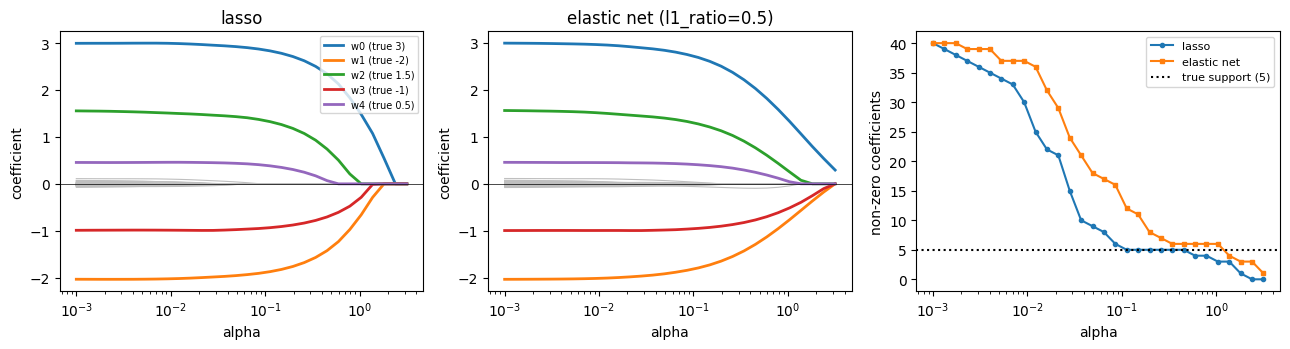

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
a = np.asarray(alphas)
for ax, path, title in [(axes[0], lasso_path, 'lasso'), (axes[1], enet_path, 'elastic net (l1_ratio=0.5)')]:
    path = np.asarray(path)
    ax.semilogx(a, path[:, 5:], color='0.75', lw=0.8)
    for j in range(5):
        ax.semilogx(a, path[:, j], lw=2, label=f'w{j} (true {coef_true[j]:g})')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('alpha'); ax.set_ylabel('coefficient'); ax.set_title(title)
axes[0].legend(fontsize=7)
axes[2].semilogx(a, nnz_lasso, 'o-', ms=3, label='lasso')
axes[2].semilogx(a, nnz_enet, 's-', ms=3, label='elastic net')
axes[2].axhline(5, color='k', ls=':', label='true support (5)')
axes[2].set_xlabel('alpha'); axes[2].set_ylabel('non-zero coefficients'); axes[2].legend(fontsize=8)
plt.tight_layout()

At the smallest `alpha` every coefficient is non-zero (40 of 40): with 80 samples for 40 features, the fit also follows the noise. As `alpha` grows the irrelevant coefficients drop out first, and between `alpha` = 0.113 and 0.452 the lasso selects exactly the 5 true features. Their estimates are shrunk towards zero: at `alpha=0.1`, for example, 2.851 for a true 3. Larger penalties then remove true features too, the smallest one (`w4`, true value 0.5) first. The elastic net keeps at least as many coefficients at every `alpha` (its $L_1$ part is only half as strong, and its $L_2$ part shrinks coefficients without setting them to zero); below `alpha = 1` it never gets under 6 non-zero coefficients, so in that range it never isolates the true support.

## 4. Multi-start minimization of a multimodal function

The 2-D Rastrigin function

$$f(p) = 20 + \sum_{i=1}^{2} \left(p_i^2 - 10 \cos 2\pi p_i\right), \qquad p \in [-5.12, 5.12]^2,$$

has a local minimum near every integer point of the grid and its global minimum $f = 0$ at the origin. A local optimizer finds the minimum of whichever basin it lands in, so it is run from many starts: `multistart_init` draws them uniformly in the box, and `multistart_minimize` runs L-BFGS from all of them at once (a `vmap` over a `lax.while_loop`, compiled into one program). With `bounds`, every start is optimised in an unconstrained space through a sigmoid, so the iterates never leave the box.

In [10]:
def rastrigin(p):
    return 20.0 + jnp.sum(p ** 2 - 10.0 * jnp.cos(2 * jnp.pi * p))


box = (jnp.full(2, -5.12), jnp.full(2, 5.12))
x0 = multistart_init(jax.random.PRNGKey(0), box, n_starts=512)
res = multistart_minimize(rastrigin, x0, method='lbfgs', bounds=(-5.12, 5.12), max_iter=100)

fun = np.asarray(res.fun)
print('starts:', x0.shape[0], ' converged:', int(res.converged.sum()),
      ' iterations: median %d, max %d' % (np.median(res.n_iter), int(res.n_iter.max())))
print('best start: #%d, f = %.2e at p = %s' % (int(res.best_index), float(res.best_fun), np.round(np.asarray(res.best_x), 4)))
print('it started at', np.round(np.asarray(x0[res.best_index]), 3))
print('starts reaching f < 1e-3:', int((fun < 1e-3).sum()))
levels, counts = np.unique(np.round(fun, 3), return_counts=True)
print('lowest final values (number of starts):', ', '.join(f'{l:.3f} ({c})' for l, c in zip(levels[:5], counts[:5])))
in_central = np.all(np.abs(np.asarray(x0)) < 0.5, axis=1)
print('starts inside the central basin |p_i| < 0.5:', int(in_central.sum()),
      ' of which reached f < 1e-3:', int((fun[in_central] < 1e-3).sum()))
print('starts needed before the global minimum is found:', int(np.argmax(np.minimum.accumulate(fun) < 1e-3)) + 1)

starts: 512  converged: 512  iterations: median 7, max 16
best start: #465, f = 0.00e+00 at p = [0. 0.]
it started at [0.235 0.186]
starts reaching f < 1e-3: 1
lowest final values (number of starts): 0.000 (1), 0.995 (19), 1.990 (25), 3.980 (29), 4.975 (43)
starts inside the central basin |p_i| < 0.5: 5  of which reached f < 1e-3: 1
starts needed before the global minimum is found: 466


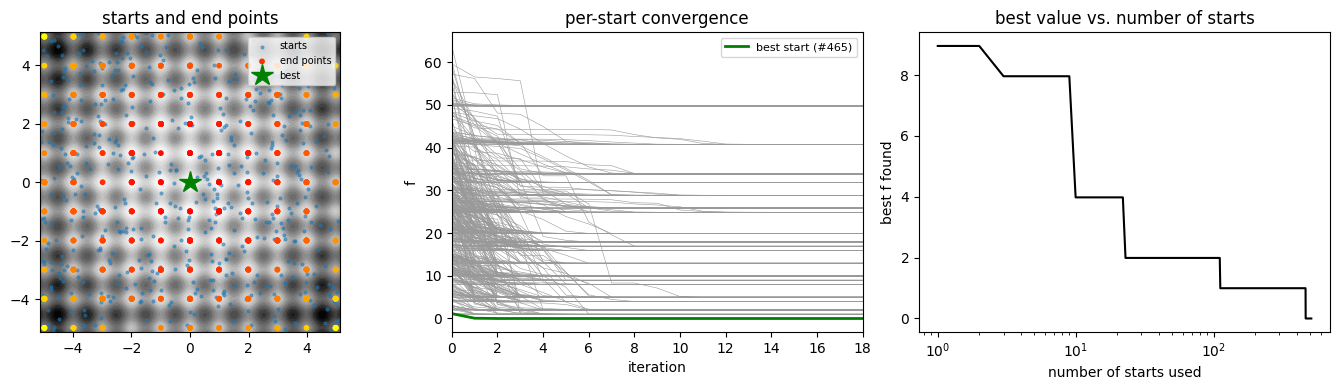

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

grid = jnp.linspace(-5.12, 5.12, 300)
P = jnp.stack(jnp.meshgrid(grid, grid), axis=-1)
F = jax.vmap(jax.vmap(rastrigin))(P)
axes[0].contourf(grid, grid, F, levels=30, cmap='Greys')
x_end = np.asarray(res.x)
axes[0].scatter(*np.asarray(x0).T, s=4, color='tab:blue', alpha=0.5, label='starts')
axes[0].scatter(*x_end.T, s=10, c=fun, cmap='autumn', label='end points')
axes[0].plot(*np.asarray(res.best_x), 'g*', ms=16, label='best')
axes[0].set_aspect('equal'); axes[0].set_title('starts and end points'); axes[0].legend(fontsize=7, loc='upper right')

history = np.asarray(res.history)
axes[1].plot(history.T, color='0.6', lw=0.4)
axes[1].plot(history[int(res.best_index)], 'g', lw=2, label=f'best start (#{int(res.best_index)})')
axes[1].set_xlim(0, int(res.n_iter.max()) + 2); axes[1].set_xlabel('iteration'); axes[1].set_ylabel('f')
axes[1].set_title('per-start convergence'); axes[1].legend(fontsize=8)

best_so_far = np.minimum.accumulate(fun)
axes[2].semilogx(np.arange(1, len(fun) + 1), best_so_far, 'k')
axes[2].set_xlabel('number of starts used'); axes[2].set_ylabel('best f found')
axes[2].set_title('best value vs. number of starts')
plt.tight_layout()

All 512 starts converged within 16 iterations (median 7), but each one only to a nearby local minimum: the end points sit on the integer grid (left panel), and the final values form discrete levels (0.995, 1.990, 3.980, ...). Only one start, #465, reached the global minimum $f = 0$ at the origin. It started at (0.235, 0.186), inside the central basin. Of the 5 starts drawn in that basin, the other 4 ended in neighbouring minima: an early L-BFGS line-search step can carry a start over a basin boundary. Because the starts are independent, the best value among the first $S$ starts (right panel) shows what a smaller run would have found: it falls in steps as $S$ grows, and this draw needs 466 starts before the global minimum is found.

## Summary

- `FORCE` (and `RLS`) update registered readout weights from `(inputs, outputs, targets)`; the update is a `brainstate` state change, so the whole training run is one `for_loop`.
- With forgetting factor 1, RLS reproduces `ridge_regression` on the samples seen so far; `LMS` is cheaper but slower, has a learning-rate stability limit, and keeps a noise floor at a constant learning rate.
- `lasso_regression` and `elastic_net_regression` are jit- and vmap-compatible, so a regularisation path over `alpha` is a single `jax.vmap`.
- `multistart_minimize` runs a local optimizer from many starts in one compiled program and reports every start's result, iteration count and loss history, with the best start picked out.